# Team \#1
## Workshop Open Tools — Vera Rubin Observatory

```Author: Sergio Sotovando```

Last update date: 15/10/2026

**Ver este notebook en [Colab](https://colab.research.google.com/github/ale-munozarancibia/LSST_Hackdays_Medellin_Team1_Characterizing_DIAObjects/blob/main/Project/ALeRCE_LSST_Team1_Crossmatch_DDF.ipynb)**

**Objetivo:** extraer SN y AGN de Rubin en un **campo Deep Drilling a elección** con ALeRCE (TAP) y cruzarlos posicionalmente con **hasta dos catálogos externos** del mismo cono usando LSDB.

| Catálogo | Para qué sirve |
|---|---|
| **AllWISE** | Colores en el infrarrojo medio → criterio de AGN (W1 − W2 ≥ 0.8, Stern et al. 2012) |
| **TNS** | Transitorios reportados → confirmar las SN y ver su tipo espectroscópico |
| **Gaia DR3** | Paralaje y movimiento propio → detectar estrellas que se colaron como AGN/SN |
| **2MASS** | Colores J, H, Ks en el infrarrojo cercano |
| **ZTF DR14 / DR23** | Fotometría óptica de otro survey de variabilidad (solo cielo norte, Dec ≳ −30°) |
| **GALEX** | Ultravioleta (FUV, NUV) → AGN/QSO suelen ser brillantes en UV |

1. **Sección 2:** se pregunta qué campo DDF estudiar.
2. Rubin (ALeRCE, `tid = 1`) → SN/AGN con `classifier_id = 3`, `probability ≥ 0.6`, `n_det ≥ 50`, y limpieza de `oid` duplicados (misma fuente con varios `diaObject`)
3. **Sección 4:** se pregunta con qué catálogo(s) hacer el crossmatch (máximo 2).
4. Crossmatch nativo con LSDB y verificación con Astropy
5. Análisis específico de cada catálogo elegido, links a ALeRCE y tabla final

> Para correr todo sin preguntas (por ejemplo, *Run all* desatendido), llená `FIELD_PRESET` en la sección 2 y `CATALOGS_PRESET` en la sección 4.

## 1. Paquetes

In [1]:
!pip install pyvo lsdb alerce s3fs

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyvo
import lsdb
from upath import UPath
from IPython.display import display

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, join

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)

print("LSDB:", lsdb.__version__)

LSDB: 0.11.0


## 2. Configuración del campo

Campos Deep Drilling de Rubin hasta el momento:

| | ELAISS1 | XMM_LSS | ECDFS | COSMOS | EDFS_a | EDFS_b |
|---|---|---|---|---|---|---|
| RA | 9.45 | 35.57 | 52.98 | 150.11 | 58.9 | 63.6 |
| Dec | -44.02 | -4.82 | -28.12 | 2.23 | -49.32 | -47.6 |
| Gal l | 311.29 | 171.1 | 224.07 | 236.78 | 257.9 | 254.48 |
| Gal b | -72.88 | -58.91 | -54.6 | 42.13 | -48.46 | -45.77 |
| Eclip l | 346.66 | 31.59 | 40.81 | 151.39 | 32 | 40.97 |
| Eclip b | -43.2 | -17.92 | -45.44 | -9.34 | -66.61 | -66.6 |

Además se ofrece **EDFS** (a + b juntos): un solo cono centrado entre los dos apuntados, con radio ≈ 3.09°, como en el notebook anterior de EDFS.

Radio por defecto: 2° (el campo de LSSTCam tiene ≈ 1.75° de radio, así que 2° deja un margen). Se usa **el mismo cono** para Rubin y para los catálogos externos.

La celda siguiente **pregunta** el campo y el radio. Enter = valor por defecto.

In [3]:
# nombre: (RA [deg], Dec [deg], radio por defecto [arcsec])
DDF_FIELDS = {
    "ELAISS1": (9.45,   -44.02,  7200.0),
    "XMM_LSS": (35.57,   -4.82,  7200.0),
    "ECDFS":   (52.98,  -28.12,  7200.0),
    "COSMOS":  (150.11,   2.23,  7200.0),
    "EDFS_a":  (58.90,  -49.32,  7200.0),
    "EDFS_b":  (63.60,  -47.60,  7200.0),
    "EDFS":    (61.25,  -48.46, 11124.7),   # EDFS_a + EDFS_b en un solo cono (~3.09 deg)
}
DEFAULT_FIELD = "ECDFS"

# Para no preguntar: FIELD_PRESET = "ECDFS" (y opcionalmente RADIUS_PRESET_DEG = 2.0)
FIELD_PRESET = None
RADIUS_PRESET_DEG = None


def _norm(s):
    return str(s).strip().lower().replace(" ", "").replace("_", "").replace("-", "")


def ask_field():
    names = list(DDF_FIELDS)
    print("Campos Deep Drilling disponibles:\n")
    print(f"  {'#':>2}  {'Campo':<8} {'RA':>8} {'Dec':>8} {'radio [deg]':>12}")
    for i, n in enumerate(names, 1):
        ra, dec, r = DDF_FIELDS[n]
        print(f"  {i:>2}  {n:<8} {ra:>8.2f} {dec:>8.2f} {r / 3600:>12.2f}")
    print()
    lookup = {_norm(n): n for n in names}
    while True:
        ans = input(f"¿Qué campo quieres estudiar? (número o nombre, Enter = {DEFAULT_FIELD}): ").strip()
        if ans == "":
            return DEFAULT_FIELD
        if ans.isdigit() and 1 <= int(ans) <= len(names):
            return names[int(ans) - 1]
        if _norm(ans) in lookup:
            return lookup[_norm(ans)]
        print(f"  '{ans}' no es una opción válida. Intenta de nuevo.")


def ask_radius(default_deg):
    while True:
        ans = input(f"Radio del cono en grados (Enter = {default_deg:.3f}): ").strip().replace(",", ".")
        if ans == "":
            return default_deg
        try:
            r = float(ans)
            if 0 < r <= 5:
                return r
        except ValueError:
            pass
        print("  Escribe un número entre 0 y 5 (grados).")


if FIELD_PRESET is not None:
    FIELD = {_norm(n): n for n in DDF_FIELDS}[_norm(FIELD_PRESET)]
    RA0, DEC0, _r_def = DDF_FIELDS[FIELD]
    radius_deg = RADIUS_PRESET_DEG if RADIUS_PRESET_DEG is not None else _r_def / 3600.0
else:
    FIELD = ask_field()
    RA0, DEC0, _r_def = DDF_FIELDS[FIELD]
    radius_deg = ask_radius(_r_def / 3600.0)

RADIUS_ARCSEC = radius_deg * 3600.0

_c = SkyCoord(RA0 * u.deg, DEC0 * u.deg)
print(f"\nCampo elegido: {FIELD}")
print(f"  RA = {RA0}, Dec = {DEC0}, radio = {radius_deg:.3f} deg ({RADIUS_ARCSEC:.1f}\")")
print(f"  Galácticas: l = {_c.galactic.l.deg:.2f}, b = {_c.galactic.b.deg:.2f}")

Campos Deep Drilling disponibles:

   #  Campo          RA      Dec  radio [deg]
   1  ELAISS1      9.45   -44.02         2.00
   2  XMM_LSS     35.57    -4.82         2.00
   3  ECDFS       52.98   -28.12         2.00
   4  COSMOS     150.11     2.23         2.00
   5  EDFS_a      58.90   -49.32         2.00
   6  EDFS_b      63.60   -47.60         2.00
   7  EDFS        61.25   -48.46         3.09

¿Qué campo quieres estudiar? (número o nombre, Enter = ECDFS): COSMOS
Radio del cono en grados (Enter = 2.000): 2.5

Campo elegido: COSMOS
  RA = 150.11, Dec = 2.23, radio = 2.500 deg (9000.0")
  Galácticas: l = 236.79, b = 42.13


## 3. Rubin desde ALeRCE (TAP)

En la base multisurvey de ALeRCE (`alerce_tap.*`) Rubin/LSST tiene `tid = 1`. El `classifier_id = 3` es el stamp classifier de Rubin.

In [4]:
TAP_URL = "https://tap.alerce.online/tap"
tap_service = pyvo.dal.TAPService(TAP_URL)

def tap_query(query, maxrec=10_000_000):
    result = tap_service.search(query, maxrec=maxrec)
    return result.to_table().to_pandas()

tid = 1             # Rubin/LSST
sid = 1             # diaObjects
classifier_id = 3   # stamp_classifier_rubin_beta_20260421

PROB_MIN = 0.6
NDET_MIN = 50

In [5]:
query = f'''
SELECT
    *
FROM alerce_tap.object AS obj
JOIN alerce_tap.probability AS prob
    ON obj.oid = prob.oid AND obj.sid = prob.sid
JOIN alerce_tap.taxonomy AS tax
    ON prob.classifier_id = tax.classifier_id
   AND prob.class_id = tax.class_id
WHERE
    obj.tid = {tid}
    AND obj.sid = {sid}
    AND prob.classifier_id = {classifier_id}
    AND tax.class_name IN ('SN', 'AGN')
    AND prob.probability >= {PROB_MIN}
    AND obj.n_det >= {NDET_MIN}
    AND CONTAINS(POINT('ICRS', obj.meanra, obj.meandec),
                 CIRCLE('ICRS', {RA0:.7g}, {DEC0:.7g}, {radius_deg:g})) = 1
'''
df_agn_sn = tap_query(query)

print(f"diaObjects SN/AGN en {FIELD}: {len(df_agn_sn)}")
if len(df_agn_sn) == 0:
    raise RuntimeError(f"ALeRCE no devolvió SN/AGN en {FIELD} con estos cortes. "
                       "Prueba otro campo, un radio mayor o cortes más laxos (PROB_MIN, NDET_MIN).")
display(df_agn_sn["class_name"].value_counts())

diaObjects SN/AGN en COSMOS: 4132


class_name
AGN    4064
SN       68
Name: count, dtype: int64

### 3.1 Tabla limpia de Rubin

El JOIN deja columnas duplicadas (`oid_`, `sid_`, `classifier_id_`, ...). Se conservan solo las útiles.

In [6]:
RUBIN_COLS = ["oid", "meanra", "meandec", "sigmara", "sigmadec",
              "firstmjd", "lastmjd", "n_det", "class_name", "probability"]

df_rubin = (df_agn_sn[RUBIN_COLS]
            .drop_duplicates("oid")
            .reset_index(drop=True))
print(df_rubin.shape)
df_rubin.head()

(4132, 10)


,oid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,n_det,class_name,probability
0,313853517432881258,151.317651,2.395209,3.226148e-07,3.192603e-07,61024.245933,61098.275586,677,SN,0.981252
1,170019716347723894,150.738630,3.353262,1.057523e-06,1.111497e-06,61088.211979,61098.273166,307,SN,0.889586
2,313853517466435621,149.261449,1.291220,3.933202e-07,3.914734e-07,61024.245933,61097.322517,705,SN,0.934199
3,170094456400773135,149.635684,1.269348,4.094198e-07,4.186182e-07,61105.095334,61179.992111,105,SN,0.833545
4,313853533120102559,149.178763,2.419444,3.592296e-07,3.526919e-07,61024.320829,61190.973753,755,SN,0.777391


### 3.2 Limpieza de duplicados: misma fuente con varios `oid`

`drop_duplicates("oid")` solo quita filas repetidas del JOIN. Pero Rubin puede crear **más de un `diaObject` (distinto `oid`) para la misma fuente del cielo**, por ejemplo uno de la serie `170…` y otro de la `313…`. Esos gemelos se cuentan dos veces en todas las estadísticas y cruzan con la misma contraparte externa (en EDFS, el TNS `2026emf` quedó asociado a dos AGN distintos).

Procedimiento:
1. Self-match de `df_rubin` con radio `DEDUP_RADIUS_ARCSEC` (1″ por defecto; la astrometría de Rubin es de décimas de segundo de arco).
2. Se agrupan los `oid` conectados (si A≈B y B≈C, los tres son un mismo grupo).
3. En cada grupo se conserva el `oid` con más detecciones (`n_det`) y, si empatan, el de mayor `probability`.
4. Los grupos cuyos `oid` tienen **clases distintas** (uno AGN y otro SN) se marcan con `conflicto_clase`:
   - `CONFLICTOS = "marcar"` (por defecto): se conserva el representante y el grupo completo se lista para revisarlo (sección 8.1).
   - `CONFLICTOS = "excluir"`: el grupo completo sale del análisis.

Se guardan `df_rubin_all` (tabla sin limpiar), `df_duplicados` (todos los `oid` de grupos con gemelos) y `dup_info` (trazabilidad por representante, pasa a la tabla final).

Este paso va **antes** del crossmatch para que las fracciones de match, los criterios de color y los links ya salgan sin dobles conteos.

In [7]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

DEDUP_RADIUS_ARCSEC = 1.0
CONFLICTOS = "marcar"   # "marcar" o "excluir"

df_rubin_all = df_rubin.copy()   # índice 0..N-1, alineado con las posiciones de coords

coords = SkyCoord(df_rubin_all["meanra"].to_numpy(float) * u.deg,
                  df_rubin_all["meandec"].to_numpy(float) * u.deg)
i1, i2, sep2d, _ = coords.search_around_sky(coords, DEDUP_RADIUS_ARCSEC * u.arcsec)
pares = i1 < i2                     # quita autopares y el par repetido (j, i)
i1, i2 = i1[pares], i2[pares]
sep_pares = sep2d[pares].to_value(u.arcsec)

# Grupos = componentes conexas del grafo de pares cercanos
n_obj = len(df_rubin_all)
grafo = coo_matrix((np.ones(len(i1)), (i1, i2)), shape=(n_obj, n_obj))
_, etiquetas = connected_components(grafo, directed=False)

g = df_rubin_all.assign(grupo=etiquetas)
g["n_oids_grupo"] = g.groupby("grupo")["oid"].transform("size")
g["conflicto_clase"] = g.groupby("grupo")["class_name"].transform("nunique") > 1

# Representante por grupo: más detecciones y, si empatan, mayor probabilidad
g = g.sort_values(["grupo", "n_det", "probability"], ascending=[True, False, False])
g["es_representante"] = ~g.duplicated("grupo")
g["oid_representante"] = g["grupo"].map(g.loc[g["es_representante"]].set_index("grupo")["oid"])

df_duplicados = g[g["n_oids_grupo"] > 1].copy()

descartados = (g.loc[~g["es_representante"]].groupby("oid_representante")["oid"]
               .agg(lambda s: ",".join(map(str, s))))
reps = g[g["es_representante"]]
if CONFLICTOS == "excluir":
    reps = reps[~reps["conflicto_clase"]]

dup_info = (reps[["oid", "n_oids_grupo", "conflicto_clase"]]
            .assign(oids_descartados=lambda d: d["oid"].map(descartados).fillna(""))
            .reset_index(drop=True))
df_rubin = reps[RUBIN_COLS].reset_index(drop=True)

Radio de self-match: 1.0"
Objetos de Rubin: 4132 antes → 4013 después de limpiar
Grupos con más de un oid: 119 (238 oid involucrados, 119 descartados)
Grupos con clases distintas (AGN y SN): 0 → política: CONFLICTOS = 'marcar'


,antes,después
class_name,,
AGN,4064,3946
SN,68,67


,grupo,oid,class_name,probability,n_det,es_representante,conflicto_clase
42,24,170046104332140686,SN,0.894058,111,True,False
24,24,170028517483872405,SN,0.881370,101,False,False
...,...,...,...,...,...,...,...
3865,3680,313980948584071292,AGN,0.809331,332,True,False
3771,3680,313967766153461816,AGN,0.606780,309,False,False


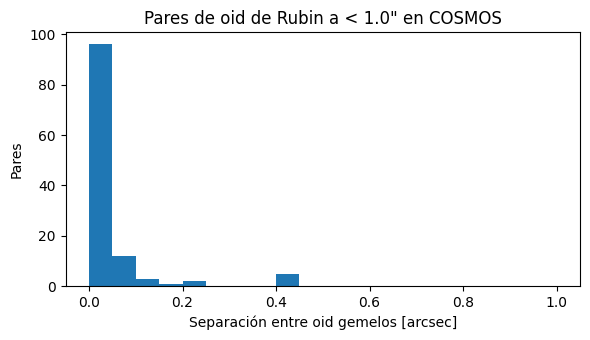

In [8]:
n_grupos_dup = df_duplicados["grupo"].nunique()
n_conf = df_duplicados.loc[df_duplicados["conflicto_clase"], "grupo"].nunique()
print(f"Radio de self-match: {DEDUP_RADIUS_ARCSEC}\"")
print(f"Objetos de Rubin: {len(df_rubin_all)} antes → {len(df_rubin)} después de limpiar")
print(f"Grupos con más de un oid: {n_grupos_dup} "
      f"({len(df_duplicados)} oid involucrados, {int((~df_duplicados['es_representante']).sum())} descartados)")
print(f"Grupos con clases distintas (AGN y SN): {n_conf} → política: CONFLICTOS = '{CONFLICTOS}'")

display(pd.DataFrame({"antes": df_rubin_all["class_name"].value_counts(),
                      "después": df_rubin["class_name"].value_counts()}).fillna(0).astype(int))

if len(df_duplicados):
    display(df_duplicados[["grupo", "oid", "class_name", "probability", "n_det",
                           "es_representante", "conflicto_clase"]]
            .sort_values(["conflicto_clase", "grupo", "es_representante"],
                         ascending=[False, True, False]))

    # Los gemelos reales se acumulan cerca de 0"; si hay muchos pares cerca del borde
    # del radio, probablemente son vecinos distintos y conviene bajar DEDUP_RADIUS_ARCSEC.
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist(sep_pares, bins=np.linspace(0, DEDUP_RADIUS_ARCSEC, 21))
    ax.set_xlabel("Separación entre oid gemelos [arcsec]")
    ax.set_ylabel("Pares")
    ax.set_title(f"Pares de oid de Rubin a < {DEDUP_RADIUS_ARCSEC}\" en {FIELD}")
    plt.tight_layout()
    plt.show()

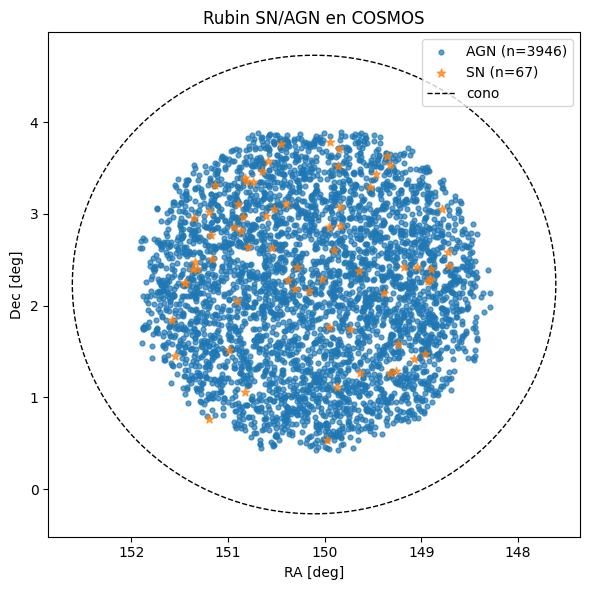

In [9]:
# Vista del campo: posiciones de los objetos de Rubin dentro del cono
fig, ax = plt.subplots(figsize=(6, 6))
for cls, marker in [("AGN", "o"), ("SN", "*")]:
    s = df_rubin[df_rubin["class_name"] == cls]
    ax.scatter(s["meanra"], s["meandec"], s=12 if cls == "AGN" else 40, marker=marker,
               alpha=0.7, label=f"{cls} (n={len(s)})")
t = np.linspace(0, 2 * np.pi, 400)
ax.plot(RA0 + radius_deg * np.cos(t) / np.cos(np.radians(DEC0)),
        DEC0 + radius_deg * np.sin(t), "k--", lw=1, label="cono")
ax.invert_xaxis()
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title(f"Rubin SN/AGN en {FIELD}")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Rubin como catálogo LSDB

La tabla de ALeRCE se convierte en catálogo HATS en memoria para poder cruzarla con `crossmatch` de LSDB.

In [10]:
rubin_cat = lsdb.from_dataframe(df_rubin, ra_column="meanra", dec_column="meandec",
                                catalog_name="rubin_agn_sn")
rubin_cat

,oid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,n_det,class_name,probability
npartitions=1,,,,,,,,,,
"Order: 1, Pixel: 26",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],large_string[pyarrow],float[pyarrow]


## 4. Catálogos de LSDB

La celda siguiente **pregunta** con qué catálogo(s) hacer el crossmatch. Se pueden elegir **hasta 2**, separados por coma (por ejemplo `1,3` o `AllWISE, Gaia DR3`).

| # | Catálogo | Fuente HATS | Radio de match | Cobertura |
|---|---|---|---|---|
| 1 | AllWISE | data.lsdb.io | 2″ | todo el cielo |
| 2 | TNS | data.lsdb.io | 2″ | todo el cielo |
| 3 | Gaia DR3 | CDS (vizcat) | 1″ | todo el cielo |
| 4 | 2MASS | data.lsdb.io | 2″ | todo el cielo |
| 5 | ZTF DR14 | data.lsdb.io | 1.5″ | solo Dec ≳ −30° |
| 6 | ZTF DR23 | IRSA (S3 público) | 1.5″ | solo Dec ≳ −30° |
| 7 | GALEX | MAST (S3 público) | 3″ | casi todo el cielo, lejos del plano galáctico |

Notas:
- **ZTF** observa desde Palomar: ELAISS1, EDFS y gran parte de ECDFS quedan fuera de su cobertura, así que ahí casi no habrá matches.
- El radio de match sigue el tamaño del PSF de cada survey (GALEX tiene PSF de ~5″, por eso 3″). Se puede cambiar en `CATALOG_LIBRARY`.
- `columns` es una lista de columnas candidatas: se usan solo las que existan (sin distinguir mayúsculas), y siempre se agregan RA/Dec del catálogo. `None` = columnas por defecto del catálogo.
- `key_cols` son las columnas que pasan a la tabla final (sección 9).

In [11]:
CATALOG_LIBRARY = {
    "AllWISE": dict(
        url="https://data.lsdb.io/hats/wise/allwise",
        radius_arcsec=2.0, n_neighbors=1, suffix="_wise",
        columns=["designation", "source_id", "ra", "dec",
                 "w1mpro", "w1sigmpro", "w2mpro", "w2sigmpro",
                 "w3mpro", "w3sigmpro", "w4mpro", "w4sigmpro",
                 "ext_flg", "cc_flags", "ph_qual"],
        key_cols=["designation", "w1mpro", "w2mpro", "w3mpro"],
    ),
    "TNS": dict(
        url="https://data.lsdb.io/hats/tns",
        radius_arcsec=2.0, n_neighbors=1, suffix="_tns",
        columns=None,   # TNS es pequeño: se conservan todas las columnas
        key_cols=["name", "type", "redshift", "discoverydate"],
    ),
    "Gaia DR3": dict(
        url="https://vizcat.cds.unistra.fr/hats:n=1000000/gaia_dr3/",
        radius_arcsec=1.0, n_neighbors=1, suffix="_gaia",
        # Nombres de Gaia archive y de VizieR (CDS); se usan los que existan
        columns=["source_id", "Source", "ra", "dec", "RA_ICRS", "DE_ICRS",
                 "parallax", "parallax_error", "Plx", "e_Plx",
                 "pmra", "pmra_error", "pmdec", "pmdec_error",
                 "pmRA", "e_pmRA", "pmDE", "e_pmDE",
                 "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag",
                 "Gmag", "BPmag", "RPmag", "bp_rp", "BP-RP", "ruwe",
                 "classprob_dsc_combmod_quasar", "classprob_dsc_combmod_galaxy",
                 "PQSO", "PGal"],
        key_cols=["source_id", "Source", "phot_g_mean_mag", "Gmag", "parallax", "Plx"],
    ),
    "2MASS": dict(
        url="https://data.lsdb.io/hats/two_mass",
        radius_arcsec=2.0, n_neighbors=1, suffix="_2mass",
        columns=["designation", "ra", "dec",
                 "j_m", "j_msigcom", "h_m", "h_msigcom", "k_m", "k_msigcom",
                 "ph_qual", "rd_flg", "cc_flg", "gal_contam", "ext_key"],
        key_cols=["designation", "j_m", "h_m", "k_m"],
    ),
    "ZTF DR14": dict(
        url="https://data.lsdb.io/hats/ztf_dr14",
        radius_arcsec=1.5, n_neighbors=1, suffix="_ztf14",
        columns=["ps1_objid", "ra", "dec",
                 "mean_mag_g", "mean_mag_r", "mean_mag_i",
                 "nobs_g", "nobs_r", "nobs_i",
                 "ps1_gMeanPSFMag", "ps1_rMeanPSFMag", "ps1_iMeanPSFMag"],
        key_cols=["ps1_objid", "mean_mag_g", "mean_mag_r", "nobs_g", "nobs_r"],
    ),
    "ZTF DR23": dict(
        url="s3://ipac-irsa-ztf/contributed/dr23/objects/hats",
        radius_arcsec=1.5, n_neighbors=1, suffix="_ztf23",
        # Tabla de objetos de IRSA: una fila por objeto y filtro
        columns=["oid", "ra", "dec", "filterid", "field",
                 "nobs", "ngoodobs", "refmag", "refmagerr",
                 "meanmag", "medianmag", "magrms", "stetsonj", "vonneumannratio"],
        key_cols=["oid", "filterid", "meanmag", "magrms", "ngoodobs"],
    ),
    "GALEX": dict(
        url="s3://stpubdata/galex/public/hats/galex/",
        radius_arcsec=3.0, n_neighbors=1, suffix="_galex",
        columns=["objid", "ra", "dec",
                 "fuv_mag", "fuv_magerr", "nuv_mag", "nuv_magerr",
                 "fuv_artifact", "nuv_artifact", "e_bv"],
        key_cols=["objid", "fuv_mag", "nuv_mag"],
    ),
}
MAX_CATALOGS = 2
DEFAULT_CATALOGS = ["AllWISE", "TNS"]

# Para no preguntar: CATALOGS_PRESET = ["AllWISE", "Gaia DR3"]
CATALOGS_PRESET = None


# Nombres cortos aceptados al responder
ALIASES = {"wise": "AllWISE", "gaia": "Gaia DR3", "dr3": "Gaia DR3", "twomass": "2MASS",
           "ztf14": "ZTF DR14", "dr14": "ZTF DR14", "ztf23": "ZTF DR23", "dr23": "ZTF DR23"}


def catalog_lookup():
    lookup = {_norm(n): n for n in CATALOG_LIBRARY}
    lookup.update(ALIASES)
    return lookup


def ask_catalogs():
    names = list(CATALOG_LIBRARY)
    lookup = catalog_lookup()
    print("Catálogos disponibles:\n")
    for i, n in enumerate(names, 1):
        print(f"  {i}  {n:<9} (radio {CATALOG_LIBRARY[n]['radius_arcsec']}\")")
    print()
    while True:
        ans = input(f"¿Con qué catálogo(s) hago el crossmatch? Máximo {MAX_CATALOGS}, "
                    f"separados por coma (Enter = {', '.join(DEFAULT_CATALOGS)}): ").strip()
        if ans == "":
            return list(DEFAULT_CATALOGS)
        chosen, bad = [], []
        for tok in ans.replace(";", ",").split(","):
            tok = tok.strip()
            if not tok:
                continue
            if tok.isdigit() and 1 <= int(tok) <= len(names):
                chosen.append(names[int(tok) - 1])
            elif _norm(tok) in lookup:
                chosen.append(lookup[_norm(tok)])
            else:
                bad.append(tok)
        chosen = list(dict.fromkeys(chosen))   # sin repetidos, en orden
        if bad:
            print(f"  No reconozco: {bad}. Intenta de nuevo.")
        elif not chosen:
            print("  Elige al menos un catálogo.")
        elif len(chosen) > MAX_CATALOGS:
            print(f"  Elegiste {len(chosen)}; el máximo es {MAX_CATALOGS}.")
        else:
            return chosen


if CATALOGS_PRESET is not None:
    lookup = catalog_lookup()
    SELECTED_CATALOGS = list(dict.fromkeys(lookup[_norm(n)] for n in CATALOGS_PRESET))[:MAX_CATALOGS]
else:
    SELECTED_CATALOGS = ask_catalogs()

EXTERNAL_CATALOGS = {n: CATALOG_LIBRARY[n] for n in SELECTED_CATALOGS}
print(f"\nCatálogos elegidos para {FIELD}: {SELECTED_CATALOGS}")

dec_min = DEC0 - radius_deg
for n in SELECTED_CATALOGS:
    if n.startswith("ZTF") and dec_min < -30:
        print(f"  Aviso: {n} cubre solo Dec ≳ −30°. El cono de {FIELD} llega a Dec = {dec_min:.1f}°, "
              "así que puede haber pocos o ningún match.")

cone = lsdb.ConeSearch(RA0, DEC0, radius_arcsec=RADIUS_ARCSEC)

Catálogos disponibles:

  1  AllWISE   (radio 2.0")
  2  TNS       (radio 2.0")
  3  Gaia DR3  (radio 1.0")
  4  2MASS     (radio 2.0")
  5  ZTF DR14  (radio 1.5")
  6  ZTF DR23  (radio 1.5")
  7  GALEX     (radio 3.0")

¿Con qué catálogo(s) hago el crossmatch? Máximo 2, separados por coma (Enter = AllWISE, TNS): Gaia DR3, ZTF DR14

Catálogos elegidos para COSMOS: ['Gaia DR3', 'ZTF DR14']


In [12]:
def as_path(url):
    # Los buckets S3 públicos (IRSA, MAST) se leen sin credenciales
    return UPath(url, anon=True) if str(url).startswith("s3://") else url


def match_columns(requested, available):
    # Devuelve las columnas pedidas que existen, sin distinguir mayúsculas
    low = {c.lower(): c for c in available}
    found = [low[c.lower()] for c in requested if c.lower() in low]
    return list(dict.fromkeys(found))


def open_external(name, cfg, search_filter):
    # Abre un catálogo HATS externo restringido al cono,
    # con solo las columnas pedidas que existan.
    path = as_path(cfg["url"])
    meta = lsdb.open_catalog(path)
    info = meta.hc_structure.catalog_info
    ra_col, dec_col = info.ra_column, info.dec_column
    available = list(getattr(meta, "all_columns", meta.columns))

    if cfg["columns"] is None:
        cols = None
    else:
        cols = match_columns(cfg["columns"], available)
        for c in (ra_col, dec_col):
            if c not in cols:
                cols.append(c)
        if len(cols) <= 2:
            # Ninguna columna pedida existe: mejor cargar las de por defecto que solo RA/Dec
            print(f"  [{name}] ninguna columna pedida existe; se usan las columnas por defecto.")
            cols = None

    cat = lsdb.open_catalog(path, columns=cols, search_filter=search_filter)
    print(f"{name}: RA='{ra_col}', Dec='{dec_col}', {len(cat.columns)} columnas")
    return cat, ra_col, dec_col


ext = {}
for name, cfg in EXTERNAL_CATALOGS.items():
    try:
        cat, ra_col, dec_col = open_external(name, cfg, cone)
        ext[name] = dict(cat=cat, ra=ra_col, dec=dec_col, **cfg)
    except Exception as err:
        print(f"No se pudo abrir {name} ({cfg['url']}): {type(err).__name__}: {err}")

print("\nCatálogos listos:", list(ext))
if not ext:
    raise RuntimeError("No se pudo abrir ningún catálogo externo. Revisa la conexión o elige otros.")

Gaia DR3: RA='RA_ICRS', Dec='DE_ICRS', 16 columnas
ZTF DR14: RA='ra', Dec='dec', 12 columnas

Catálogos listos: ['Gaia DR3', 'ZTF DR14']


In [13]:
# Vista rápida de cada catálogo en el campo
for name, e in ext.items():
    print(f"=== {name} ===")
    print(list(e["cat"].columns))
    display(e["cat"].head(3))

=== Gaia DR3 ===
['Source', 'RA_ICRS', 'DE_ICRS', 'Plx', 'e_Plx', 'pmRA', 'e_pmRA', 'pmDE', 'e_pmDE', 'Gmag', 'BPmag', 'RPmag', 'BP-RP', 'RUWE', 'PQSO', 'PGal']


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,Source,RA_ICRS,DE_ICRS,Plx,e_Plx,pmRA,e_pmRA,pmDE,e_pmDE,Gmag,BPmag,RPmag,BP-RP,RUWE,PQSO,PGal
122663,3833124755377390208,149.147462,-0.073933,0.418725,0.094897,-6.473971,0.098959,2.093561,0.096121,16.938053,17.340446,16.365774,0.974672,1.131876,0.0,0.0
122664,3833124755378189440,149.143733,-0.073515,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,20.7437,21.28624,19.798763,1.487476,<NA>,0.000157,0.000014
122665,3833124824096867072,149.12747,-0.067027,2.476632,0.122597,-5.020296,0.13557,-26.467215,0.153055,17.466908,18.694092,16.380405,2.313686,0.964217,0.0,0.0


=== ZTF DR14 ===
['ps1_objid', 'ra', 'dec', 'mean_mag_g', 'mean_mag_r', 'mean_mag_i', 'nobs_g', 'nobs_r', 'nobs_i', 'ps1_gMeanPSFMag', 'ps1_rMeanPSFMag', 'ps1_iMeanPSFMag']


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,ps1_objid,ra,dec,mean_mag_g,mean_mag_r,mean_mag_i,nobs_g,nobs_r,nobs_i,ps1_gMeanPSFMag,ps1_rMeanPSFMag,ps1_iMeanPSFMag
_healpix_29,,,,,,,,,,,,
1916562383904239242,107911491474951740,149.147465,-0.073919,17.428385,16.850464,16.689156,237,358,27,17.402599,16.901699,16.716999
1916562385381206068,107911491437372231,149.143742,-0.073513,21.214294,20.558589,20.212988,18,137,11,21.451,20.629299,20.334
1916562393042881725,107911491380286144,149.138041,-0.070345,<NA>,21.676356,20.271286,0,13,10,-999.0,21.3978,20.472401


## 5. Crossmatch con LSDB

`how="left"` conserva **todos** los objetos de Rubin: los que no tienen contraparte quedan con `_dist_arcsec = NaN`. Así se puede calcular directamente la fracción con match por clase.

In [14]:
def to_pandas(df):
    # pyarrow dtypes → numpy-nullable (más fácil de manipular y de pasar a Astropy)
    return pd.DataFrame(df).reset_index(drop=True).convert_dtypes(dtype_backend="numpy_nullable")


def lsdb_crossmatch(name, e):
    kwargs = dict(radius_arcsec=e["radius_arcsec"], n_neighbors=e["n_neighbors"],
                  how="left", suffixes=("_rubin", e["suffix"]))
    try:
        # Mantiene el comportamiento actual (sufijo en todas las columnas) y evita el FutureWarning
        xm_cat = rubin_cat.crossmatch(e["cat"], suffix_method="all_columns", **kwargs)
    except TypeError:
        xm_cat = rubin_cat.crossmatch(e["cat"], **kwargs)
    df = to_pandas(xm_cat.compute())
    # Quitar el sufijo _rubin para que las columnas de Rubin conserven su nombre original
    df = df.rename(columns={f"{c}_rubin": c for c in RUBIN_COLS})
    df["has_match"] = df["_dist_arcsec"].notna()
    return df


xm = {}
for name, e in ext.items():
    xm[name] = lsdb_crossmatch(name, e)
    n = xm[name].loc[xm[name]["has_match"], "oid"].nunique()
    print(f"{name}: {n} de {df_rubin['oid'].nunique()} objetos Rubin con contraparte "
          f"(radio {e['radius_arcsec']}\")")

Computing Catalog:   0%|          | 0/11 [00:00<?, ?it/s]

Gaia DR3: 2397 de 4013 objetos Rubin con contraparte (radio 1.0")


Computing Catalog:   0%|          | 0/11 [00:00<?, ?it/s]

ZTF DR14: 3559 de 4013 objetos Rubin con contraparte (radio 1.5")


### 5.1 Resumen por clase

In [15]:
def best_match(name):
    # Mejor contraparte (la más cercana) por objeto de Rubin, solo los que tienen match
    df = xm[name]
    return (df[df["has_match"]].sort_values("_dist_arcsec")
            .drop_duplicates("oid").copy())


rows = []
for name, df in xm.items():
    best = df.sort_values("_dist_arcsec").drop_duplicates("oid")
    g = best.groupby("class_name")["has_match"].agg(["size", "sum"])
    for cls, r in g.iterrows():
        rows.append(dict(catalogo=name, clase=cls, n_rubin=int(r["size"]),
                         n_con_match=int(r["sum"]), fraccion=r["sum"] / r["size"]))

summary = pd.DataFrame(rows).pivot(index="clase", columns="catalogo",
                                   values=["n_con_match", "fraccion"])
summary.insert(0, "n_rubin", df_rubin.groupby("class_name").size())
display(summary)

n_rubin n_con_match           fraccion          
catalogo            Gaia DR3 ZTF DR14  Gaia DR3  ZTF DR14
clase                                                    
AGN         3946      2390.0   3524.0  0.605677  0.893056
SN            67         7.0     35.0  0.104478  0.522388

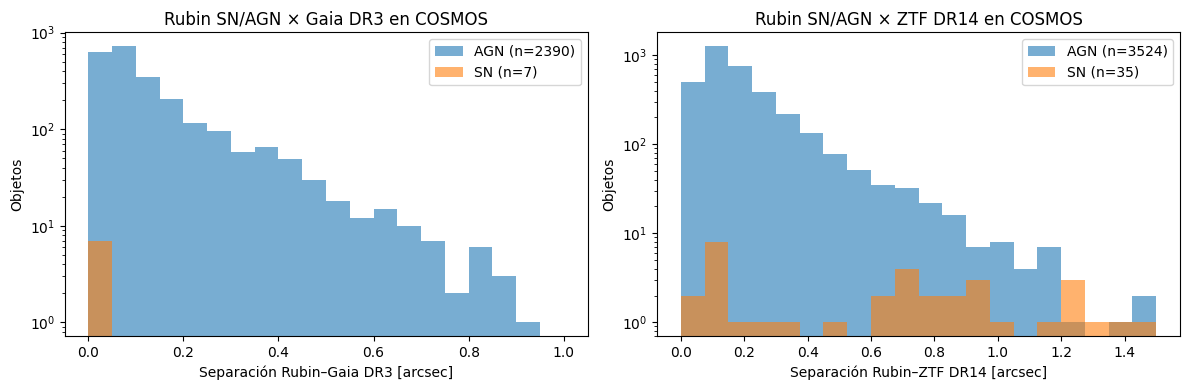

In [16]:
fig, axes = plt.subplots(1, len(xm), figsize=(6 * len(xm), 4), squeeze=False)
for i, (ax, (name, df)) in enumerate(zip(axes[0], xm.items())):
    for cls in ["AGN", "SN"]:
        sep = df.loc[df["has_match"] & (df["class_name"] == cls), "_dist_arcsec"].astype(float)
        ax.hist(sep, bins=np.linspace(0, ext[name]["radius_arcsec"], 21), alpha=0.6,
                label=f"{cls} (n={len(sep)})")
    ax.set_xlabel(f"Separación Rubin–{name} [arcsec]")
    ax.set_ylabel("Objetos")
    ax.set_title(f"Rubin SN/AGN × {name} en {FIELD}")
    ax.set_yscale("log")
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Verificación con Astropy

Mismo crossmatch pero siguiendo el esqueleto del equipo: catálogo externo → pandas → `astropy.Table` → `SkyCoord.search_around_sky`. Debe dar el mismo número de objetos con match que LSDB.

Para catálogos grandes (Gaia, ZTF) en conos grandes esto descarga todo el cono; se puede apagar con `VERIFICAR_ASTROPY = False`.

In [17]:
VERIFICAR_ASTROPY = True


def astropy_crossmatch(table_1, table_2, ra_1, dec_1, ra_2, dec_2,
                       match_radius=1.0 * u.arcsec,
                       table_names=("table1", "table2")):
    # Crossmatch posicional de dos tablas de Astropy.
    # Devuelve todos los pares dentro de match_radius, ordenados por separación.
    coord_1 = SkyCoord(ra=np.asarray(table_1[ra_1], dtype=float) * u.deg,
                       dec=np.asarray(table_1[dec_1], dtype=float) * u.deg)
    coord_2 = SkyCoord(ra=np.asarray(table_2[ra_2], dtype=float) * u.deg,
                       dec=np.asarray(table_2[dec_2], dtype=float) * u.deg)

    idx_1, idx_2, separation, _ = coord_2.search_around_sky(coord_1, match_radius)

    if len(idx_1) == 0:
        # Sin pares dentro del radio: astropy.join no acepta tablas vacías
        print(f"Sin matches dentro de {match_radius}.")
        return Table()

    matched_1 = table_1[idx_1].copy()
    matched_2 = table_2[idx_2].copy()

    match_id = np.arange(len(idx_1), dtype=int)
    matched_1["match_id"] = match_id
    matched_2["match_id"] = match_id
    matched_1["separation_arcsec"] = separation.to_value(u.arcsec)

    crossmatch = join(matched_1, matched_2, keys="match_id", join_type="inner",
                      table_names=list(table_names),
                      uniq_col_name="{col_name}_{table_name}")
    crossmatch.sort("separation_arcsec")
    return crossmatch

In [18]:
xm_astropy = {}
if VERIFICAR_ASTROPY:
    table_1 = Table.from_pandas(df_rubin)
    for name, e in ext.items():
        df_ext = to_pandas(e["cat"].compute())
        # Para verificar el match basta con columnas numéricas (evita problemas con texto/anidadas)
        df_ext = df_ext.select_dtypes(include="number")
        table_2 = Table.from_pandas(df_ext)

        res = astropy_crossmatch(table_1, table_2, "meanra", "meandec", e["ra"], e["dec"],
                                 match_radius=e["radius_arcsec"] * u.arcsec,
                                 table_names=("rubin", e["suffix"].lstrip("_")))
        xm_astropy[name] = res
        # Si el catálogo externo también tiene "oid" (ZTF DR23), el de Rubin queda como "oid_rubin"
        oid_col = "oid_rubin" if "oid_rubin" in res.colnames else "oid"
        n_astropy = len(set(res[oid_col])) if len(res) else 0
        n_lsdb = xm[name].loc[xm[name]["has_match"], "oid"].nunique()
        print(f"{name}: {len(df_ext):,} fuentes en el campo | "
              f"objetos con match → Astropy: {n_astropy}, LSDB: {n_lsdb}")
else:
    print("Verificación con Astropy desactivada.")

Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

Gaia DR3: 76,882 fuentes en el campo | objetos con match → Astropy: 2397, LSDB: 2397


Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

ZTF DR14: 340,795 fuentes en el campo | objetos con match → Astropy: 3559, LSDB: 3559


## 7. Análisis por catálogo

Cada subsección corre solo si ese catálogo fue elegido en la sección 4. Las columnas se buscan con y sin sufijo (`_wise`, `_gaia`, ...) y sin distinguir mayúsculas, porque los nombres cambian entre proveedores.

In [19]:
derivados = {}   # columnas calculadas por catálogo, se agregan a la tabla final


def catcol(df, name, candidates):
    # Busca la primera columna candidata, con o sin sufijo del catálogo, sin distinguir mayúsculas
    suf = CATALOG_LIBRARY[name]["suffix"]
    low = {c.lower(): c for c in df.columns}
    for c in candidates:
        for v in (f"{c}{suf}", c):
            if v.lower() in low:
                return low[v.lower()]
    return None


def num(df, col):
    if col is None:
        return pd.Series(np.nan, index=df.index, dtype=float)
    return pd.to_numeric(df[col], errors="coerce").astype(float)


def no_seleccionado(name):
    print(f"{name} no fue elegido en la sección 4; se omite este análisis.")

### 7.1 AllWISE: criterio de color en el infrarrojo medio

Los AGN calientan polvo que emite en el infrarrojo medio, así que son más rojos en W1 − W2 que las estrellas y las galaxias normales. El criterio clásico de **Stern et al. (2012)** es **W1 − W2 ≥ 0.8** (magnitudes Vega, que es lo que dan las columnas `w*mpro` de AllWISE), confiable para W2 ≲ 15.

Si el clasificador de Rubin funciona bien, la mayoría de los AGN con contraparte en WISE deberían cumplirlo y las SN (cuyas anfitrionas son galaxias normales) no.

In [20]:
if "AllWISE" in xm:
    wise = best_match("AllWISE")
    wise["W1"] = num(wise, catcol(wise, "AllWISE", ["w1mpro"]))
    wise["W2"] = num(wise, catcol(wise, "AllWISE", ["w2mpro"]))
    wise["W3"] = num(wise, catcol(wise, "AllWISE", ["w3mpro"]))
    wise["W1_W2"] = wise["W1"] - wise["W2"]
    wise["W2_W3"] = wise["W2"] - wise["W3"]
    wise["agn_stern12"] = wise["W1_W2"] >= 0.8
    wise["W2_brillante"] = wise["W2"] <= 15.05

    display(wise.groupby("class_name")["agn_stern12"].agg(n="size", cumplen_W1W2="sum"))
    display(wise[["oid", "class_name", "probability", "_dist_arcsec",
                  "W1", "W2", "W3", "W1_W2", "W2_W3", "agn_stern12"]]
            .sort_values(["class_name", "W1_W2"], ascending=[True, False]))
    derivados["AllWISE"] = wise[["oid", "W1_W2", "W2_W3", "agn_stern12"]]

    fig, ax = plt.subplots(figsize=(7, 5.5))
    for cls, marker in [("AGN", "o"), ("SN", "*")]:
        s = wise[wise["class_name"] == cls]
        ax.scatter(s["W2_W3"], s["W1_W2"], marker=marker, s=40, alpha=0.7,
                   label=f"Rubin {cls} (n={len(s)})")
    ax.axhline(0.8, ls="--", color="k", lw=1, label="W1−W2 = 0.8 (Stern+12)")
    ax.set_xlabel("W2 − W3 [Vega]")
    ax.set_ylabel("W1 − W2 [Vega]")
    ax.set_title(f"Diagrama color-color WISE de SN/AGN de Rubin en {FIELD}")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    no_seleccionado("AllWISE")

AllWISE no fue elegido en la sección 4; se omite este análisis.


### 7.2 Gaia DR3: estrellas que se colaron

Un AGN o una SN extragaláctica no deberían tener paralaje ni movimiento propio medibles. Se marca como **posible estrella** si la paralaje o el movimiento propio son significativos a más de 5σ. Un AGN de Rubin marcado así probablemente es una estrella variable mal clasificada (o el match en Gaia es una estrella vecina).

Si el catálogo trae la probabilidad de cuásar del clasificador DSC de Gaia (`classprob_dsc_combmod_quasar` / `PQSO`), también se muestra.

,n,posibles_estrellas
class_name,,
AGN,2390,1482
SN,7,0


,oid,class_name,probability,_dist_arcsec,G,BP_RP,plx_snr,pm_snr,posible_estrella,P_quasar_gaia
734,313994141163847687,AGN,0.854068,0.812287,16.556931,2.798657,122.767532,1107.210668,True,1.136378e-13
279,313985345856208922,AGN,0.748288,0.736491,16.697021,2.612082,71.463724,1012.488396,True,1.196147e-13
...,...,...,...,...,...,...,...,...,...,...
0,313980947920846861,SN,0.892891,0.022782,19.897810,1.455584,NaN,NaN,False,0.000000e+00
4,313875415101865999,SN,0.763727,0.025219,19.437542,1.376126,NaN,NaN,False,0.000000e+00


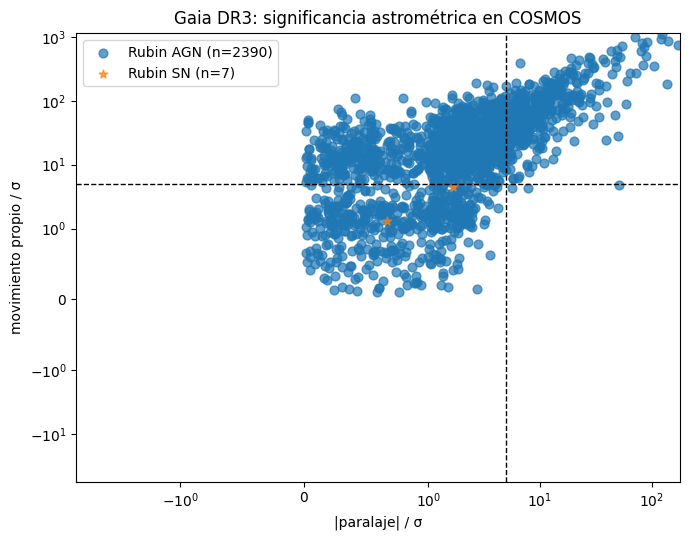

In [21]:
if "Gaia DR3" in xm:
    gaia = best_match("Gaia DR3")
    G = "Gaia DR3"
    plx, eplx = num(gaia, catcol(gaia, G, ["parallax", "plx"])), num(gaia, catcol(gaia, G, ["parallax_error", "e_plx"]))
    pmra, epmra = num(gaia, catcol(gaia, G, ["pmra"])), num(gaia, catcol(gaia, G, ["pmra_error", "e_pmra"]))
    pmde, epmde = num(gaia, catcol(gaia, G, ["pmdec", "pmde"])), num(gaia, catcol(gaia, G, ["pmdec_error", "e_pmde"]))

    gaia["G"] = num(gaia, catcol(gaia, G, ["phot_g_mean_mag", "gmag"]))
    bprp_col = catcol(gaia, G, ["bp_rp", "bp-rp"])
    if bprp_col:
        gaia["BP_RP"] = num(gaia, bprp_col)
    else:
        gaia["BP_RP"] = (num(gaia, catcol(gaia, G, ["phot_bp_mean_mag", "bpmag"]))
                         - num(gaia, catcol(gaia, G, ["phot_rp_mean_mag", "rpmag"])))
    gaia["plx_snr"] = plx / eplx
    gaia["pm_snr"] = np.hypot(pmra / epmra, pmde / epmde)
    gaia["posible_estrella"] = (gaia["plx_snr"].abs() > 5) | (gaia["pm_snr"] > 5)

    pqso_col = catcol(gaia, G, ["classprob_dsc_combmod_quasar", "pqso"])
    cols_show = ["oid", "class_name", "probability", "_dist_arcsec",
                 "G", "BP_RP", "plx_snr", "pm_snr", "posible_estrella"]
    if pqso_col:
        gaia["P_quasar_gaia"] = num(gaia, pqso_col)
        cols_show.append("P_quasar_gaia")

    display(gaia.groupby("class_name")["posible_estrella"].agg(n="size", posibles_estrellas="sum"))
    display(gaia[cols_show].sort_values(["class_name", "pm_snr"], ascending=[True, False]))
    derivados["Gaia DR3"] = gaia[[c for c in ["oid", "G", "BP_RP", "plx_snr", "pm_snr",
                                              "posible_estrella", "P_quasar_gaia"] if c in gaia]]

    fig, ax = plt.subplots(figsize=(7, 5.5))
    for cls, marker in [("AGN", "o"), ("SN", "*")]:
        s = gaia[gaia["class_name"] == cls]
        ax.scatter(s["plx_snr"].abs(), s["pm_snr"], marker=marker, s=40, alpha=0.7,
                   label=f"Rubin {cls} (n={len(s)})")
    ax.axvline(5, ls="--", color="k", lw=1)
    ax.axhline(5, ls="--", color="k", lw=1)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xlabel("|paralaje| / σ")
    ax.set_ylabel("movimiento propio / σ")
    ax.set_title(f"Gaia DR3: significancia astrométrica en {FIELD}")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    no_seleccionado("Gaia DR3")

### 7.3 2MASS: colores en el infrarrojo cercano

Diagrama J − H vs H − Ks (magnitudes Vega). Las estrellas se concentran en H − Ks ≲ 0.3; las galaxias y los AGN tienden a ser más rojos en H − Ks.

In [22]:
if "2MASS" in xm:
    tm = best_match("2MASS")
    tm["J"] = num(tm, catcol(tm, "2MASS", ["j_m", "jmag"]))
    tm["H"] = num(tm, catcol(tm, "2MASS", ["h_m", "hmag"]))
    tm["Ks"] = num(tm, catcol(tm, "2MASS", ["k_m", "ks_m", "kmag"]))
    tm["J_H"] = tm["J"] - tm["H"]
    tm["H_Ks"] = tm["H"] - tm["Ks"]
    tm["J_Ks"] = tm["J"] - tm["Ks"]

    display(tm.groupby("class_name")[["J", "J_H", "H_Ks", "J_Ks"]].median().round(2))
    display(tm[["oid", "class_name", "probability", "_dist_arcsec", "J", "H", "Ks", "J_H", "H_Ks"]]
            .sort_values(["class_name", "H_Ks"], ascending=[True, False]))
    derivados["2MASS"] = tm[["oid", "J_H", "H_Ks", "J_Ks"]]

    fig, ax = plt.subplots(figsize=(7, 5.5))
    for cls, marker in [("AGN", "o"), ("SN", "*")]:
        s = tm[tm["class_name"] == cls]
        ax.scatter(s["H_Ks"], s["J_H"], marker=marker, s=40, alpha=0.7,
                   label=f"Rubin {cls} (n={len(s)})")
    ax.set_xlabel("H − Ks [Vega]")
    ax.set_ylabel("J − H [Vega]")
    ax.set_title(f"Diagrama color-color 2MASS en {FIELD}")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    no_seleccionado("2MASS")

2MASS no fue elegido en la sección 4; se omite este análisis.


### 7.4 ZTF (DR14 / DR23): fotometría óptica de otro survey

ZTF da un segundo punto de vista óptico. Un AGN de Rubin con contraparte en ZTF debería mostrar variabilidad (dispersión `magrms` alta en DR23); una SN reciente normalmente **no** tiene contraparte en el objeto de referencia de ZTF, salvo su galaxia anfitriona.

- **DR14** (data.lsdb.io): magnitudes medias por filtro (`mean_mag_g`, `mean_mag_r`) y número de observaciones.
- **DR23** (IRSA): una fila por objeto **y filtro**; `filterid` 1 = g, 2 = r, 3 = i.

=== ZTF DR14: 3559 objetos Rubin con contraparte ===


,g,r,g_r,nobs_g,nobs_r
class_name,,,,,
AGN,20.97,20.16,0.64,42.0,164.0
SN,20.74,20.12,0.67,67.0,198.0


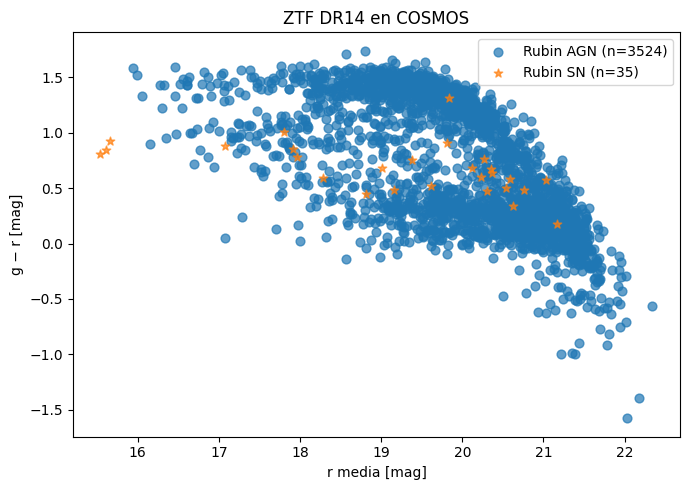

In [23]:
ztf_done = False
for Z in ["ZTF DR14", "ZTF DR23"]:
    if Z not in xm:
        continue
    ztf_done = True
    z = best_match(Z)
    print(f"=== {Z}: {len(z)} objetos Rubin con contraparte ===")
    if len(z) == 0:
        print("  Sin contrapartes (¿campo fuera de la cobertura de ZTF?).")
        continue

    if Z == "ZTF DR14":
        z["g"] = num(z, catcol(z, Z, ["mean_mag_g"]))
        z["r"] = num(z, catcol(z, Z, ["mean_mag_r"]))
        z["nobs_g"] = num(z, catcol(z, Z, ["nobs_g"]))
        z["nobs_r"] = num(z, catcol(z, Z, ["nobs_r"]))
        z["g_r"] = z["g"] - z["r"]
        display(z.groupby("class_name")[["g", "r", "g_r", "nobs_g", "nobs_r"]].median().round(2))
        derivados[Z] = z[["oid", "g", "r", "g_r"]].rename(
            columns={"g": "g_ztf14", "r": "r_ztf14", "g_r": "g_r_ztf14"})
        xcol, ycol, xlab, ylab = "r", "g_r", "r media [mag]", "g − r [mag]"
    else:
        z["filtro"] = num(z, catcol(z, Z, ["filterid"])).map({1.0: "g", 2.0: "r", 3.0: "i"})
        z["mag_ztf"] = num(z, catcol(z, Z, ["meanmag", "medianmag", "refmag"]))
        z["magrms"] = num(z, catcol(z, Z, ["magrms"]))
        z["ngoodobs"] = num(z, catcol(z, Z, ["ngoodobs", "nobs"]))
        display(z.groupby(["class_name", "filtro"])[["mag_ztf", "magrms", "ngoodobs"]].median().round(3))
        derivados[Z] = z[["oid", "filtro", "mag_ztf", "magrms"]].rename(
            columns={"filtro": "filtro_ztf23", "mag_ztf": "mag_ztf23", "magrms": "magrms_ztf23"})
        xcol, ycol, xlab, ylab = "mag_ztf", "magrms", "magnitud media ZTF [mag]", "dispersión magrms [mag]"

    fig, ax = plt.subplots(figsize=(7, 5))
    for cls, marker in [("AGN", "o"), ("SN", "*")]:
        s = z[z["class_name"] == cls]
        ax.scatter(s[xcol], s[ycol], marker=marker, s=40, alpha=0.7, label=f"Rubin {cls} (n={len(s)})")
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    ax.set_title(f"{Z} en {FIELD}")
    ax.legend()
    plt.tight_layout()
    plt.show()

if not ztf_done:
    no_seleccionado("ZTF DR14 / DR23")

### 7.5 GALEX: ultravioleta

Los cuásares/AGN no oscurecidos suelen ser brillantes en el UV cercano (NUV) y tener FUV − NUV pequeño hasta z ~ 1; las galaxias anfitrionas de SN pasivas casi no emiten en FUV. Se muestra la fracción con detección NUV/FUV y la distribución de FUV − NUV (magnitudes AB).

In [24]:
if "GALEX" in xm:
    gx = best_match("GALEX")
    gx["NUV"] = num(gx, catcol(gx, "GALEX", ["nuv_mag", "nuv_mag_best", "nuv_mag_auto", "nuv"]))
    gx["FUV"] = num(gx, catcol(gx, "GALEX", ["fuv_mag", "fuv_mag_best", "fuv_mag_auto", "fuv"]))
    # GALEX usa -999 como "sin detección"
    gx.loc[gx["NUV"] < 0, "NUV"] = np.nan
    gx.loc[gx["FUV"] < 0, "FUV"] = np.nan
    gx["FUV_NUV"] = gx["FUV"] - gx["NUV"]

    resumen_uv = gx.groupby("class_name").agg(
        n=("oid", "size"),
        con_NUV=("NUV", lambda s: int(s.notna().sum())),
        con_FUV=("FUV", lambda s: int(s.notna().sum())),
        NUV_mediana=("NUV", "median"),
        FUV_NUV_mediana=("FUV_NUV", "median"),
    )
    display(resumen_uv.round(2))
    derivados["GALEX"] = gx[["oid", "NUV", "FUV", "FUV_NUV"]]

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for cls in ["AGN", "SN"]:
        s = gx.loc[gx["class_name"] == cls, "FUV_NUV"].dropna()
        if len(s):
            ax.hist(s, bins=20, alpha=0.6, label=f"{cls} (n={len(s)})")
    ax.set_xlabel("FUV − NUV [AB]")
    ax.set_ylabel("Objetos")
    ax.set_title(f"GALEX: color UV de SN/AGN de Rubin en {FIELD}")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    no_seleccionado("GALEX")

GALEX no fue elegido en la sección 4; se omite este análisis.


### 7.6 TNS: transitorios reportados

TNS (Transient Name Server) es el registro oficial de transitorios. Un match indica que el objeto ya fue reportado; si tiene tipo espectroscópico (por ejemplo `SN Ia`, `SN II`), sirve como **verdad de referencia** para evaluar al clasificador de Rubin.

Los nombres de columna de TNS se detectan automáticamente porque pueden variar.

In [25]:
TNS_NAME = TNS_TYPE = TNS_Z = TNS_DATE = None
tns = pd.DataFrame()

if "TNS" in xm:
    tns = best_match("TNS")
    TNS_NAME = catcol(tns, "TNS", ["name", "objname", "fullname", "name_prefix"])
    TNS_TYPE = catcol(tns, "TNS", ["type", "obj_type", "objtype", "classification"])
    TNS_Z = catcol(tns, "TNS", ["redshift", "z"])
    TNS_DATE = catcol(tns, "TNS", ["discoverydate", "discovery_date", "disc_date"])
    print("Columnas TNS detectadas:", dict(nombre=TNS_NAME, tipo=TNS_TYPE, z=TNS_Z, fecha=TNS_DATE))

    show = ["oid", "class_name", "probability", "_dist_arcsec"] + \
           [c for c in (TNS_NAME, TNS_TYPE, TNS_Z, TNS_DATE) if c]
    display(tns[show].sort_values(["class_name", "_dist_arcsec"]))

    # Clase de Rubin vs. tipo en TNS
    if len(tns) and TNS_TYPE:
        tipo = tns[TNS_TYPE].astype("string").fillna("sin clasificar")
        tipo = tipo.where(tipo.str.strip() != "", "sin clasificar")
        display(pd.crosstab(tns["class_name"], tipo, margins=True))
else:
    no_seleccionado("TNS")

TNS no fue elegido en la sección 4; se omite este análisis.


**Cómo leerlo:**
- **SN de Rubin con tipo `SN …` en TNS** → acierto del clasificador.
- **SN de Rubin con tipo `AGN`/`QSO`/`TDE`/`CV`** → posible confusión del clasificador.
- **AGN de Rubin que aparecen en TNS** → alguien reportó su variabilidad como transitorio. Es común en AGN con fulguraciones; conviene revisar sus curvas de luz.
- **Sin match en TNS** → no reportado (todavía), no necesariamente falso.

### 7.7 Chequeo: una contraparte externa ↔ un solo `oid`

Después de la limpieza de la sección 3.2, ninguna fuente externa debería quedar asociada a más de un `oid` de Rubin. Si aparece alguna, puede ser un gemelo separado por más de `DEDUP_RADIUS_ARCSEC`, o dos fuentes de Rubin realmente distintas que caen dentro del radio de match del catálogo (más probable con radios grandes, como los 3″ de GALEX).

In [26]:
for name in xm:
    b = best_match(name)
    ra_c = catcol(b, name, [ext[name]["ra"]])
    dec_c = catcol(b, name, [ext[name]["dec"]])
    # Identificador de la fuente externa por posición (no depende del nombre de su columna de ID)
    b["_fuente_ext"] = num(b, ra_c).round(6).astype(str) + "_" + num(b, dec_c).round(6).astype(str)
    n_por_fuente = b.groupby("_fuente_ext")["oid"].transform("size")
    multi = b[n_por_fuente > 1]
    print(f"{name}: {multi['_fuente_ext'].nunique()} fuentes externas asociadas a más de un oid "
          f"de Rubin ({len(multi)} oid)")
    if len(multi):
        display(multi[["_fuente_ext", "oid", "class_name", "probability", "n_det", "_dist_arcsec"]]
                .sort_values(["_fuente_ext", "_dist_arcsec"]))

Gaia DR3: 0 fuentes externas asociadas a más de un oid de Rubin (0 oid)
ZTF DR14: 0 fuentes externas asociadas a más de un oid de Rubin (0 oid)


## 8. Links de inspección en ALeRCE

Para revisar a ojo curvas de luz y stamps en el explorador de ALeRCE (Rubin/LSST), ordenados por probabilidad del clasificador.

- Si se eligió **TNS**: objetos con contraparte en TNS. Prioridad de revisión: AGN de Rubin con match en TNS (reportado como transitorio, posible error) y SN de Rubin cuyo tipo en TNS no es "SN …".
- Con cualquier catálogo: `LINKS_CATALOG` permite generar links para los objetos con match en otro catálogo elegido.

In [27]:
CLASSIFIER_NAME = "stamp_classifier_rubin_beta_20260421"   # classifier_id = 3
ALERCE_LSST_URL = "https://lsst.alerce.online/?"
BATCH_SIZE = 100
TOP_N = None          # None = todos los objetos con match; o un entero para ver solo los top N
LINKS_CATALOG = "TNS" if "TNS" in xm else next(iter(xm))   # catálogo cuyos matches se inspeccionan


def alerce_url(oids, classifier_name=CLASSIFIER_NAME):
    # URL del explorador de ALeRCE con uno o varios oid
    suffix = (f"&count=true&page=1&perPage=1000&sortDesc=true"
              f"&selectedClassifier={classifier_name}")
    return ALERCE_LSST_URL + "&".join(f"oid={o}" for o in oids) + suffix


def dourlbatches(df, classifier_name, class_name, N=None, batchsize=BATCH_SIZE, catalogo=LINKS_CATALOG):
    # Imprime links en lotes para los objetos de class_name,
    # del más probable al menos probable según el clasificador.
    sel = (df.loc[df["class_name"] == class_name]
             .sort_values("probability", ascending=False))
    if N is not None:
        sel = sel.iloc[:N]
    n = sel.shape[0]
    print(f"Campo: {FIELD}\nClassifier: {classifier_name}\nClass: {class_name}\n"
          f"#objetos con match en {catalogo}: {n} "
          f"(en lotes de no más de {min(batchsize, n)} elementos)")
    for ibatch in range(int(np.ceil(n / batchsize))):
        chunk = sel.index[ibatch * batchsize:(ibatch + 1) * batchsize]
        print(f"Batch {ibatch + 1}")
        print(alerce_url(chunk, classifier_name))
    print()

In [28]:
links_df = best_match(LINKS_CATALOG).set_index("oid")   # índice = oid, como espera dourlbatches

for class_name in ["AGN", "SN"]:
    dourlbatches(links_df, CLASSIFIER_NAME, class_name, N=TOP_N, catalogo=LINKS_CATALOG)

if LINKS_CATALOG == "TNS" and len(links_df):
    tipo_tns = (links_df[TNS_TYPE].astype("string").fillna("sin clasificar")
                if TNS_TYPE else pd.Series("sin clasificar", index=links_df.index))
    nombre_tns = (links_df[TNS_NAME].astype("string")
                  if TNS_NAME else pd.Series("", index=links_df.index))

    revisar = pd.DataFrame({
        "class_name": links_df["class_name"],
        "probability": links_df["probability"].astype(float),
        "nombre_tns": nombre_tns,
        "tipo_tns": tipo_tns,
    })
    es_sn_tns = revisar["tipo_tns"].str.upper().str.startswith("SN")
    revisar["sospechoso"] = ((revisar["class_name"] == "AGN")
                             | ((revisar["class_name"] == "SN") & ~es_sn_tns
                                & (revisar["tipo_tns"] != "sin clasificar")))
    revisar = revisar.sort_values(["sospechoso", "class_name", "probability"],
                                  ascending=[False, True, False])

    print(f"=== Objetos con match en TNS en {FIELD}: {len(revisar)} "
          f"({int(revisar['sospechoso'].sum())} marcados como sospechosos) ===\n")
    for oid, r in revisar.iterrows():
        flag = "(!)" if r["sospechoso"] else "   "
        print(f"{flag} {oid}  Rubin={r['class_name']:<3} p={r['probability']:.3f}  "
              f"TNS={r['nombre_tns']} ({r['tipo_tns']})")
        print(f"      {alerce_url([oid])}")

Campo: COSMOS
Classifier: stamp_classifier_rubin_beta_20260421
Class: AGN
#objetos con match en Gaia DR3: 2390 (en lotes de no más de 100 elementos)
Batch 1
https://lsst.alerce.online/?oid=170028500609138838&oid=170028510544396398&oid=170028500603371670&oid=170028500602847438&oid=170028510538104982&oid=170028500558807154&oid=170028510491967601&oid=313972183909531813&oid=170028500579778675&oid=313853532974350370&oid=170028500553040005&oid=170028511637012735&oid=170028500594458776&oid=170028510775607455&oid=170028500612284536&oid=313994140851896352&oid=170028510563270800&oid=170028512772620432&oid=170028500540981441&oid=170028510658691176&oid=170028510489346161&oid=170028512709706238&oid=170028510676516992&oid=313888627038355604&oid=313853517493698564&oid=170028500605468803&oid=170028500624867441&oid=170028510506123401&oid=170028510771413189&oid=313853533525377135&oid=170028500585545855&oid=170028500578205819&oid=170028500551991449&oid=170028500630110340&oid=170028500626964715&oid=313888

### 8.1 Gemelos con clase en conflicto

Grupos de la sección 3.2 donde un `oid` quedó como AGN y otro como SN en la misma posición. Son candidatos interesantes de confusión del clasificador: conviene comparar ambas curvas de luz en el mismo link.

In [29]:
conf = df_duplicados[df_duplicados["conflicto_clase"]]
print(f"Grupos con clase en conflicto en {FIELD}: {conf['grupo'].nunique()} (política: '{CONFLICTOS}')\n")
for grp, d in conf.sort_values(["grupo", "es_representante"], ascending=[True, False]).groupby("grupo", sort=False):
    detalle = ", ".join(f"{o} ({c}, p={p:.2f}, n_det={n}){' ← representante' if r else ''}"
                        for o, c, p, n, r in d[["oid", "class_name", "probability", "n_det",
                                                "es_representante"]].itertuples(index=False))
    print(f"Grupo {grp}: {detalle}")
    print(f"      {alerce_url(d['oid'])}")

Grupos con clase en conflicto en COSMOS: 0 (política: 'marcar')



## 9. Tabla final y guardado

Una fila por objeto de Rubin, con la separación y las columnas clave (`key_cols`) de cada catálogo elegido, más las columnas calculadas en la sección 7.

Incluye también la trazabilidad de la limpieza de duplicados (`n_oids_grupo`, `conflicto_clase`, `oids_descartados`). La lista completa de gemelos se guarda aparte.

In [30]:
final = df_rubin.copy()
final = final.merge(dup_info, on="oid", how="left")   # trazabilidad de duplicados

for name in xm:
    b = best_match(name)
    tag = CATALOG_LIBRARY[name]["suffix"].lstrip("_")
    keep = [catcol(b, name, [c]) for c in CATALOG_LIBRARY[name]["key_cols"]]
    keep = [c for c in dict.fromkeys(keep) if c and c not in ("oid", "_dist_arcsec")]
    sub = b[["oid", "_dist_arcsec"] + keep].rename(columns={"_dist_arcsec": f"sep_{tag}_arcsec"})
    final = final.merge(sub, on="oid", how="left")

for name, d in derivados.items():
    nuevas = [c for c in d.columns if c != "oid" and c not in final.columns]
    final = final.merge(d[["oid"] + nuevas], on="oid", how="left")

display(final)

tags = "_".join(CATALOG_LIBRARY[n]["suffix"].lstrip("_") for n in xm)
final.to_csv(f"rubin_agn_sn_{FIELD}_xmatch_{tags}.csv", index=False)
for name, df in xm.items():
    df.to_csv(f"rubin_x_{CATALOG_LIBRARY[name]['suffix'].lstrip('_')}_{FIELD}.csv", index=False)
df_duplicados.to_csv(f"rubin_duplicados_{FIELD}.csv", index=False)
print("Guardado:")
print(f"  rubin_agn_sn_{FIELD}_xmatch_{tags}.csv")
for name in xm:
    print(f"  rubin_x_{CATALOG_LIBRARY[name]['suffix'].lstrip('_')}_{FIELD}.csv")
print(f"  rubin_duplicados_{FIELD}.csv")


,oid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,n_det,class_name,probability,n_oids_grupo,conflicto_clase,oids_descartados,sep_gaia_arcsec,Source_gaia,Gmag_gaia,Plx_gaia,sep_ztf14_arcsec,ps1_objid_ztf14,mean_mag_g_ztf14,mean_mag_r_ztf14,nobs_g_ztf14,nobs_r_ztf14,G,BP_RP,plx_snr,pm_snr,posible_estrella,P_quasar_gaia,g_ztf14,r_ztf14,g_r_ztf14
0,313853517432881258,151.317651,2.395209,3.226148e-07,3.192603e-07,61024.245933,61098.275586,677,SN,0.981252,1,False,,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,170019716347723894,150.738630,3.353262,1.057523e-06,1.111497e-06,61088.211979,61098.273166,307,SN,0.889586,1,False,,<NA>,<NA>,<NA>,<NA>,1.272639,112021507382374273,21.02266,20.348975,56,193,NaN,NaN,NaN,NaN,NaN,NaN,21.022660,20.348975,0.673685
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4011,170028510800248952,149.777685,1.091246,1.090769e-07,1.109028e-07,61090.181531,61204.973907,273,AGN,0.932058,1,False,,0.034491,3834426096108265856,20.100742,-0.642607,0.084252,109301497776739980,20.030655,19.802571,179,322,20.100742,0.624622,-0.981771,1.595627,False,9.999999e-01,20.030655,19.802571,0.228083
4012,313888627231293469,149.354980,0.866670,1.175140e-07,1.122654e-07,61032.328496,61204.981752,54,AGN,0.882961,1,False,,0.373667,3834368925798698496,18.596691,5.960149,0.278558,109041493551540397,20.716517,19.194748,104,310,18.596691,3.156786,19.082445,64.355990,True,1.141588e-13,20.716517,19.194748,1.521769


Guardado:
  rubin_agn_sn_COSMOS_xmatch_gaia_ztf14.csv
  rubin_x_gaia_COSMOS.csv
  rubin_x_ztf14_COSMOS.csv
  rubin_duplicados_COSMOS.csv
